# Exploratory Data Analysis: Titanic Survival

## Objective
Explore the Titanic passenger dataset to understand which factors (gender, class, age, fare, family size) influenced survival, using a structured EDA workflow:

1. Load and inspect the data
2. Check data quality (missing values, duplicates)
3. Clean the data
4. Univariate analysis
5. Bivariate / multivariate analysis
6. Feature engineering
7. Key insights

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 2. Load the Data

In [2]:
df = sns.load_dataset("titanic")
print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Data Overview

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:
df.describe(include="all").T

## 4. Data Quality Check

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct}).query("missing > 0").sort_values("percent", ascending=False)

,missing,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


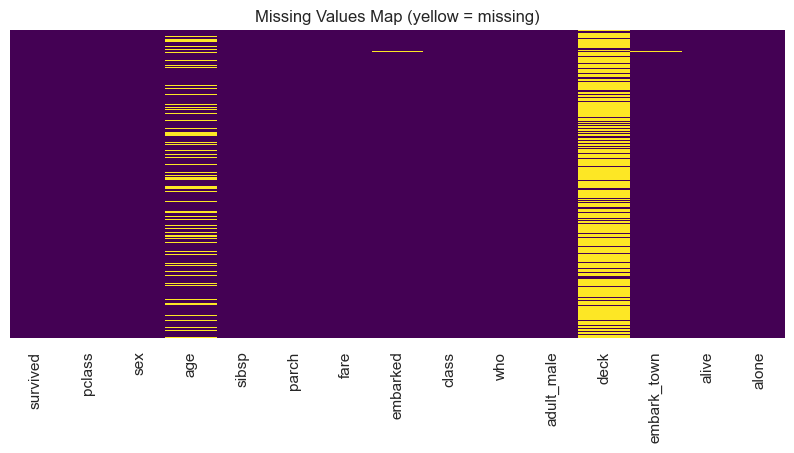

Duplicate rows: 107


In [5]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Map (yellow = missing)")
plt.show()

print("Duplicate rows:", df.duplicated().sum())

## 5. Data Cleaning

- `deck` is ~77% missing, so we drop it.
- `age` is filled with the median age of each passenger class and sex group.
- `embarked` / `embark_town` have very few gaps, so we fill them with the mode.
- Duplicate rows are removed.
- `alive`, `adult_male`, `who` and `class` duplicate other columns, so we drop them.

In [6]:
df_clean = df.copy()

df_clean = df_clean.drop(columns=["deck", "alive", "adult_male", "who", "class"])

df_clean["age"] = df_clean.groupby(["pclass", "sex"])["age"].transform(lambda x: x.fillna(x.median()))

for col in ["embarked", "embark_town"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after cleaning:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Shape after cleaning: (773, 10)
Remaining missing values: 0


## 6. Univariate Analysis

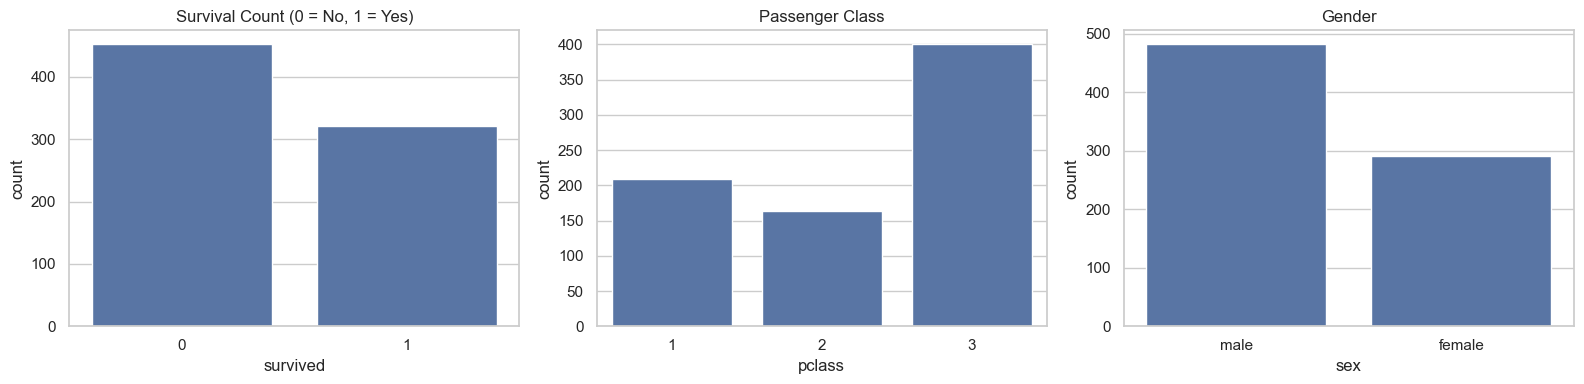

survived
0    58.5
1    41.5
Name: proportion, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="survived", data=df_clean, ax=axes[0])
axes[0].set_title("Survival Count (0 = No, 1 = Yes)")

sns.countplot(x="pclass", data=df_clean, ax=axes[1])
axes[1].set_title("Passenger Class")

sns.countplot(x="sex", data=df_clean, ax=axes[2])
axes[2].set_title("Gender")

plt.tight_layout()
plt.show()

print(df_clean["survived"].value_counts(normalize=True).round(3) * 100)

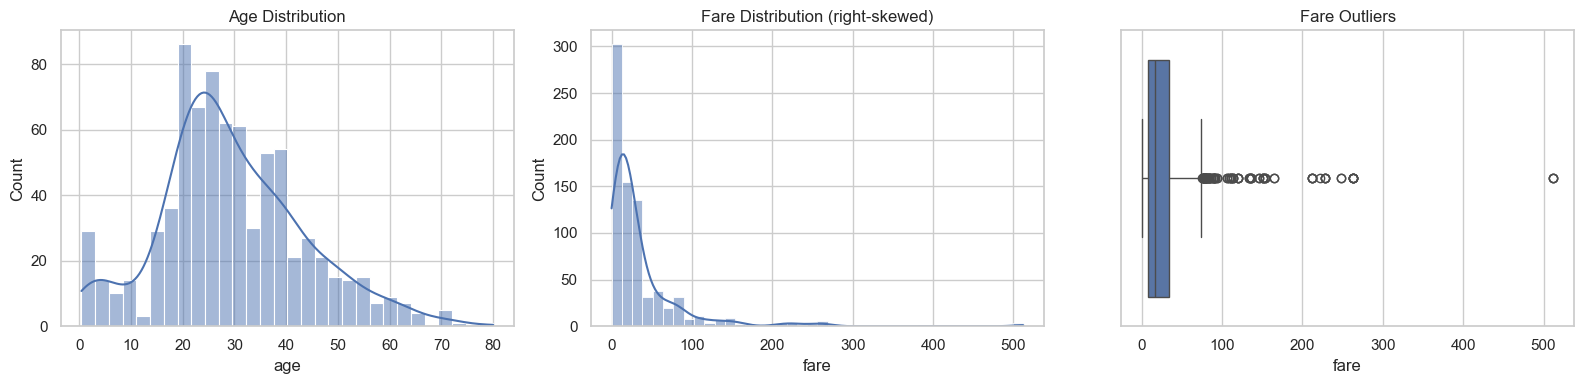

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_clean["age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(df_clean["fare"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Fare Distribution (right-skewed)")

sns.boxplot(x=df_clean["fare"], ax=axes[2])
axes[2].set_title("Fare Outliers")

plt.tight_layout()
plt.show()

## 7. Bivariate Analysis: What Affected Survival?

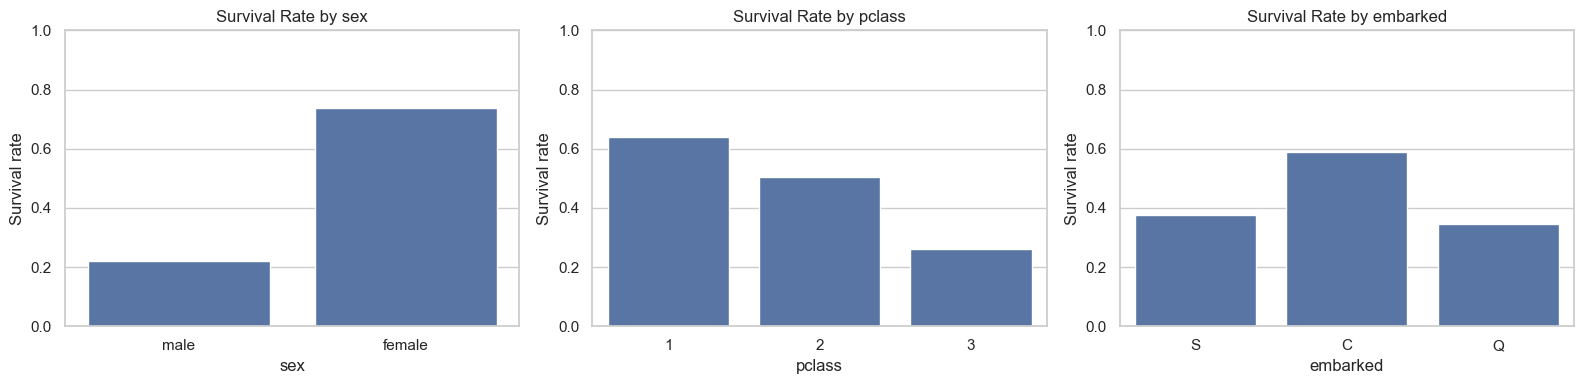

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ["sex", "pclass", "embarked"]):
    sns.barplot(x=col, y="survived", data=df_clean, errorbar=None, ax=ax)
    ax.set_title(f"Survival Rate by {col}")
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

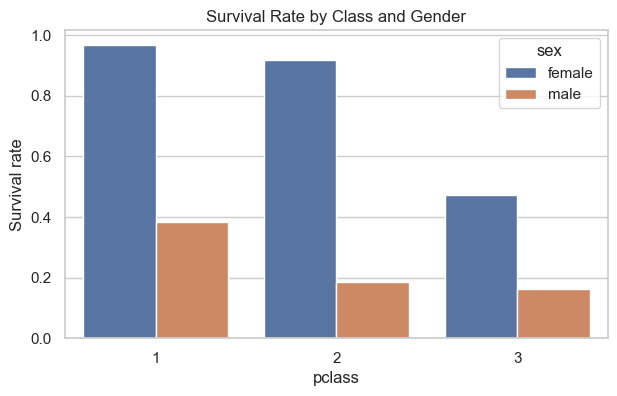

In [10]:
plt.figure(figsize=(7, 4))
sns.barplot(x="pclass", y="survived", hue="sex", data=df_clean, errorbar=None)
plt.title("Survival Rate by Class and Gender")
plt.ylabel("Survival rate")
plt.show()

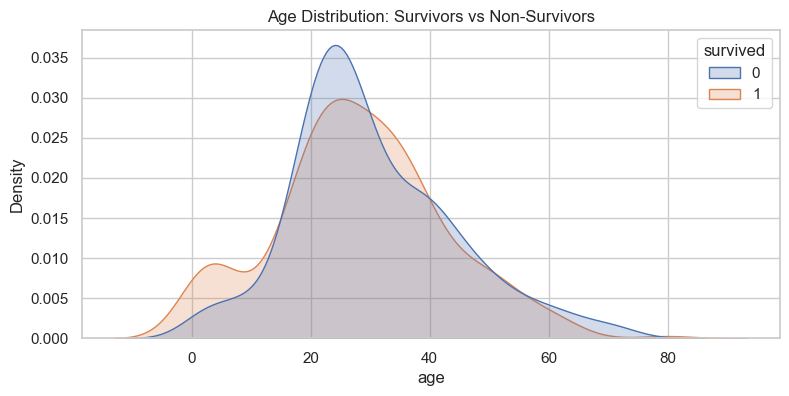

In [11]:
plt.figure(figsize=(9, 4))
sns.kdeplot(data=df_clean, x="age", hue="survived", fill=True, common_norm=False)
plt.title("Age Distribution: Survivors vs Non-Survivors")
plt.show()

## 8. Correlation Analysis

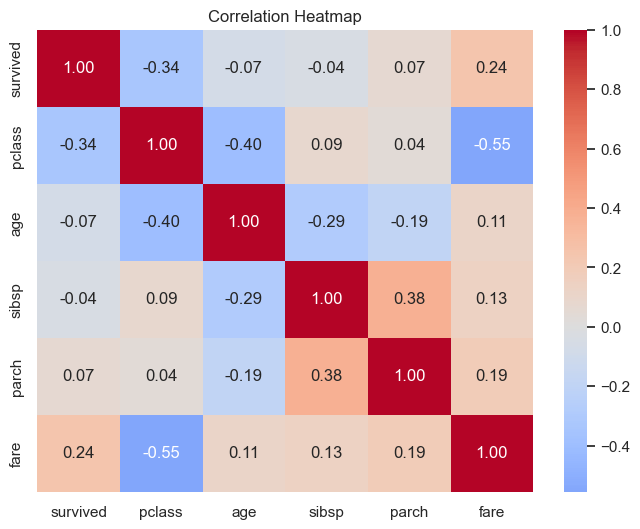

In [12]:
num_cols = df_clean.select_dtypes(include=np.number).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 9. Feature Engineering

In [13]:
df_clean["family_size"] = df_clean["sibsp"] + df_clean["parch"] + 1
df_clean["is_alone"] = (df_clean["family_size"] == 1).astype(int)

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
)

df_clean["fare_band"] = pd.qcut(df_clean["fare"], 4, labels=["Low", "Medium", "High", "Very High"])

df_clean[["family_size", "is_alone", "age_group", "fare_band"]].head()

,family_size,is_alone,age_group,fare_band
0,2,0,Young Adult,Low
1,2,0,Adult,Very High
2,1,1,Young Adult,Low
3,2,0,Young Adult,Very High
4,1,1,Young Adult,Low


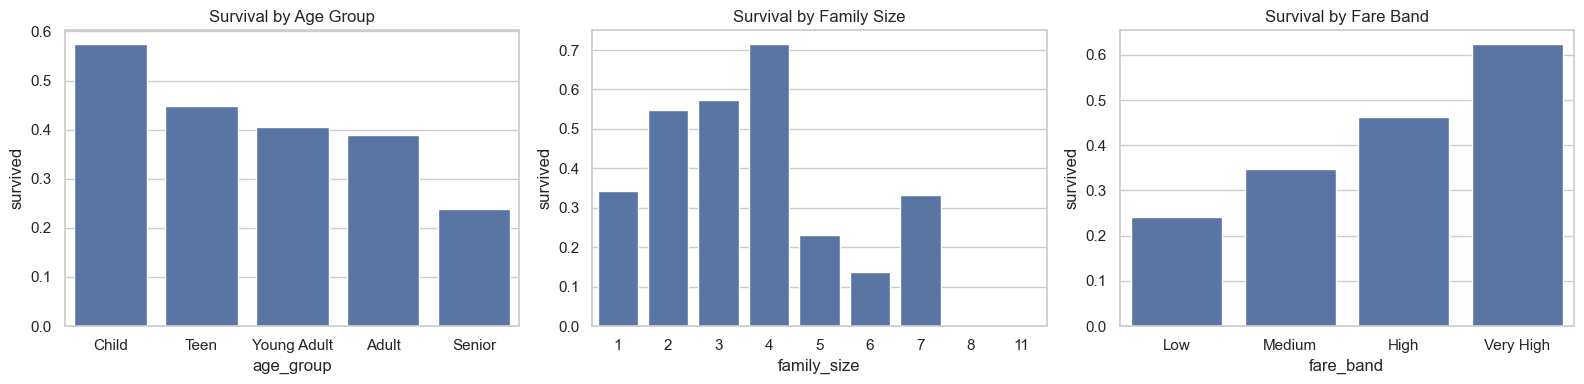

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x="age_group", y="survived", data=df_clean, errorbar=None, ax=axes[0])
axes[0].set_title("Survival by Age Group")

sns.barplot(x="family_size", y="survived", data=df_clean, errorbar=None, ax=axes[1])
axes[1].set_title("Survival by Family Size")

sns.barplot(x="fare_band", y="survived", data=df_clean, errorbar=None, ax=axes[2])
axes[2].set_title("Survival by Fare Band")

plt.tight_layout()
plt.show()

## 10. Summary Tables

In [15]:
summary = df_clean.pivot_table(
    values="survived", index="pclass", columns="sex", aggfunc="mean"
).round(3) * 100
print("Survival rate (%) by class and gender")
summary

Survival rate (%) by class and gender


sex,female,male
pclass,,
1,96.7,38.5
2,91.7,18.5
3,47.2,16.1


## 11. Key Insights

Fill these in from your own charts. Typical findings:

1. **Gender** was the strongest factor: women survived at a far higher rate than men.
2. **Passenger class** mattered: first-class passengers survived more often than third-class.
3. **Class and gender combined**: third-class women still had a much better chance than first-class men in many cases.
4. **Age**: children had a higher survival rate than other age groups.
5. **Family size**: passengers travelling alone or in very large families survived less often than those in small families (2 to 4 people).
6. **Fare**: higher fares correlate with survival, largely because fare is linked to passenger class.

## 12. Conclusion and Next Steps

- Build a predictive model (Logistic Regression, Random Forest) using the engineered features.
- Run statistical tests (chi-square for categorical features, t-test for age and fare).
- Repeat this workflow on a different dataset, such as Telco customer churn or retail sales, for your portfolio.